# DBSCAN – Density-Based Clustering (Hands-on Lab)

**Level:** Introductory to intermediate  
**Goal:** Learn how DBSCAN discovers dense groups of observations and identifies outliers without asking us to specify the number of clusters in advance.

DBSCAN stands for **Density-Based Spatial Clustering of Applications with Noise**. It is an unsupervised learning algorithm.

This notebook uses synthetic datasets so we can clearly see how DBSCAN behaves with irregularly shaped clusters, different density settings, and noise points.


## 1. What is DBSCAN?

DBSCAN groups observations that are close together in dense regions. Observations in sparse regions may be marked as noise (outliers).

Unlike K-Means:
- DBSCAN does not require the number of clusters (`k`) in advance.
- It can discover non-circular and irregularly shaped clusters.
- It can identify noise points.
- Its results depend strongly on the distance measure and density parameters.

### Three types of points

1. **Core point:** Has at least `min_samples` observations (including itself) within distance `eps`.
2. **Border point:** Is within `eps` of a core point, but does not itself have enough nearby observations to be a core point.
3. **Noise point:** Is neither a core point nor density-reachable from a core point.

### Two important parameters

- `eps`: The neighborhood radius. Two points are neighbors if their distance is at most `eps`.
- `min_samples`: The minimum number of points needed in an `eps` neighborhood for a point to be considered a core point.

A small `eps` can create many small clusters and noise points. A large `eps` can merge separate groups. These are tendencies, not guarantees.


In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_blobs
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

%matplotlib inline


## 2. Create a dataset with curved clusters

K-Means works best when clusters are roughly compact and convex. DBSCAN can discover more complex shapes.

We will use `make_moons`, which creates two interleaving crescent-shaped groups, and add a little noise.


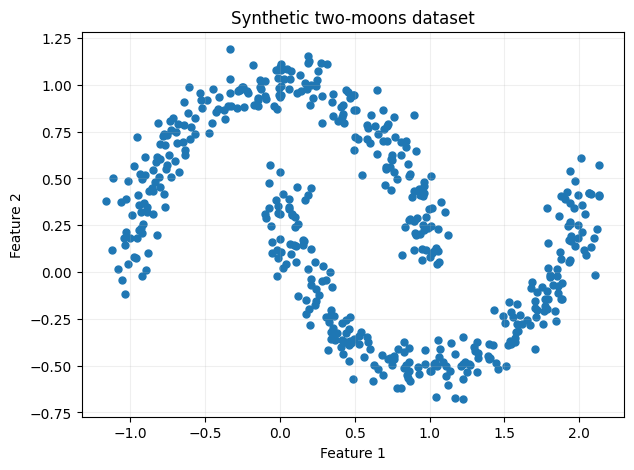

In [3]:
X, y_reference = make_moons(
    n_samples=500,
    noise=0.08,
    random_state=42
)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=25)
plt.title("Synthetic two-moons dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(alpha=0.2)
plt.show()


The `y_reference` values were created by the synthetic-data generator. We will not provide them to DBSCAN. They are available only as a reference for later discussion.

## 3. Run DBSCAN

Start with `eps=0.20` and `min_samples=5`. These are demonstration settings; later we will experiment with them.


In [4]:
dbscan = DBSCAN(eps=0.20, min_samples=5)
labels = dbscan.fit_predict(X)

unique_labels = sorted(set(labels))
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print("Cluster labels:", unique_labels)
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)


Cluster labels: [np.int64(0), np.int64(1)]
Number of clusters: 2
Number of noise points: 0


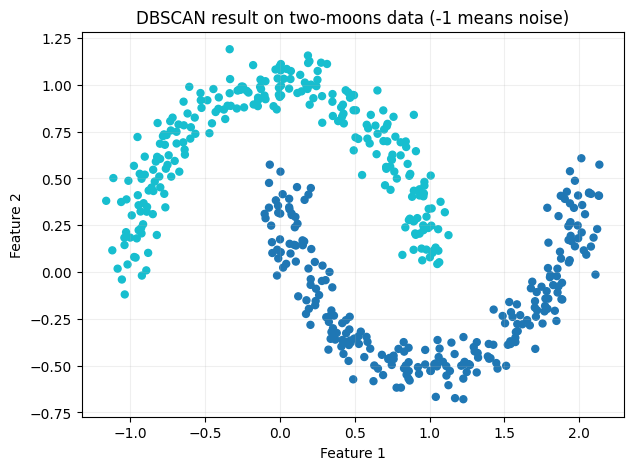

In [5]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=25)
plt.title("DBSCAN result on two-moons data (-1 means noise)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(alpha=0.2)
plt.show()


### Interpret the result

- Each non-negative label represents a cluster.
- Label `-1` represents noise points.
- Cluster numbers are arbitrary identifiers. Cluster 0 is not inherently better than cluster 1.

**Think:** Did DBSCAN find the two curved groups? How many observations did it label as noise?


## 4. Experiment with `eps` and `min_samples`

Run DBSCAN with different parameter combinations. Observe how the number of clusters and noise points change.

There is no single parameter setting that is best for every dataset.


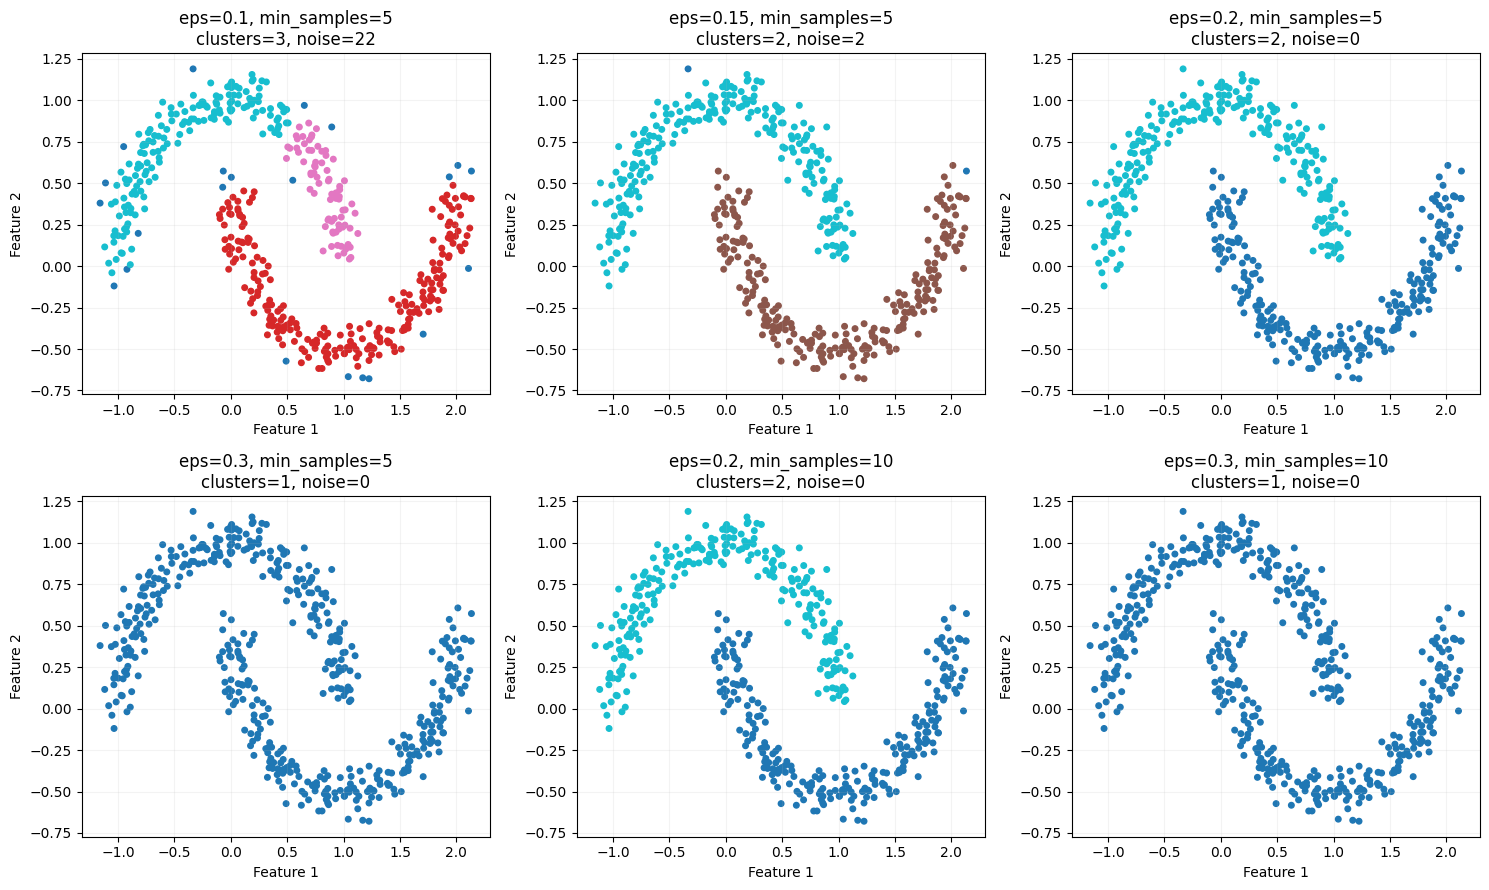

,eps,min_samples,clusters,noise_points
0,0.10,5,3,22
1,0.15,5,2,2
2,0.20,5,2,0
3,0.30,5,1,0
4,0.20,10,2,0
5,0.30,10,1,0


In [6]:
settings = [
    (0.10, 5),
    (0.15, 5),
    (0.20, 5),
    (0.30, 5),
    (0.20, 10),
    (0.30, 10),
]

experiment_results = []

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (eps_value, min_samples_value) in zip(axes.ravel(), settings):
    model = DBSCAN(eps=eps_value, min_samples=min_samples_value)
    model_labels = model.fit_predict(X)
    clusters = len(set(model_labels)) - (1 if -1 in model_labels else 0)
    noise_count = np.sum(model_labels == -1)

    experiment_results.append({
        "eps": eps_value,
        "min_samples": min_samples_value,
        "clusters": clusters,
        "noise_points": noise_count
    })

    ax.scatter(X[:, 0], X[:, 1], c=model_labels, cmap="tab10", s=16)
    ax.set_title(f"eps={eps_value}, min_samples={min_samples_value}\n"
                 f"clusters={clusters}, noise={noise_count}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

display(pd.DataFrame(experiment_results))


### Parameter interpretation

- **Increase `eps`:** Neighborhoods become larger. Nearby dense regions may connect, reducing the number of clusters; noise may decrease.
- **Decrease `eps`:** Neighborhoods become smaller. Points may fail to meet the density requirement, increasing noise or splitting clusters.
- **Increase `min_samples`:** A point needs more neighbors to qualify as a core point. This often makes the clustering more conservative and can increase noise.

## 5. Find a useful `eps` starting point with a k-distance plot

A k-distance plot can help suggest an `eps` value. For each observation, calculate the distance to its `k`-th nearest neighbor, sort those distances, and look for a bend or elbow.

This is a heuristic, not an automatic answer. The result depends on the dataset, scaling, distance metric, and chosen `k`.


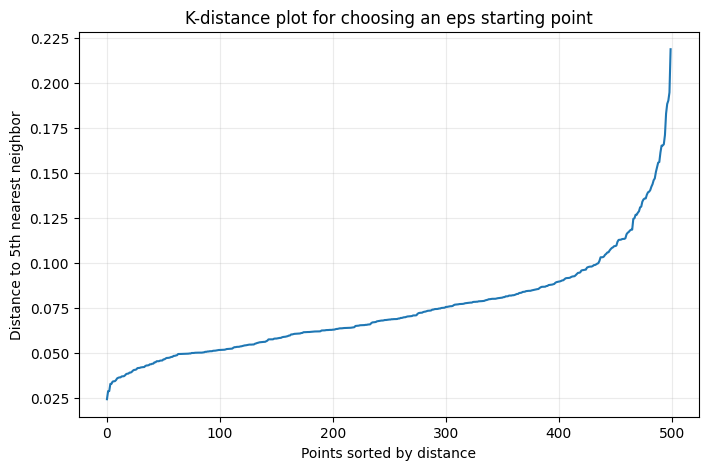

In [7]:
min_samples_value = 5

neighbors = NearestNeighbors(n_neighbors=min_samples_value)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples_value}th nearest neighbor")
plt.title("K-distance plot for choosing an eps starting point")
plt.grid(alpha=0.25)
plt.show()


**How to read it:** Look for a noticeable change in slope. The distance near that bend can be a candidate `eps`. Test nearby values and inspect the resulting clusters. Do not choose an `eps` solely from the plot without checking whether the clusters make sense for the problem.


## 6. Why feature scaling matters

DBSCAN uses distances. If one feature has a much larger numerical range than another, it can dominate the distance calculation.

We will create a dataset with two features on very different scales and compare DBSCAN before and after standardization.


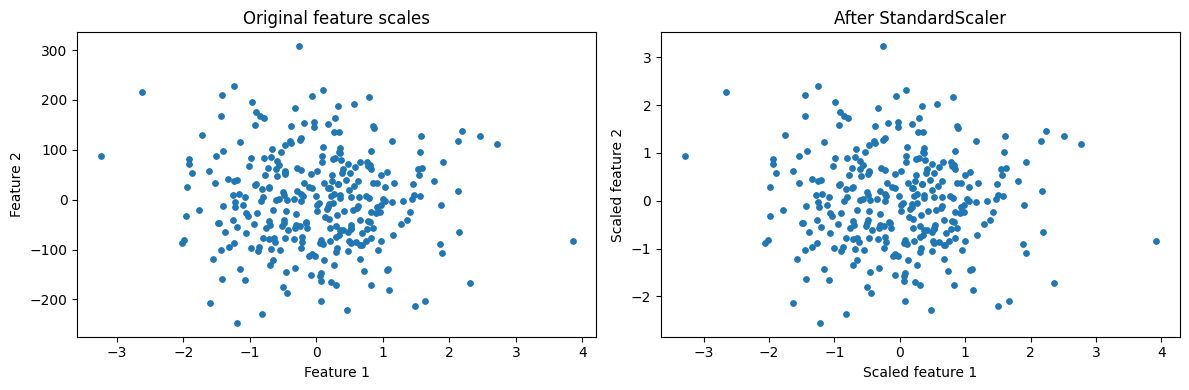

In [8]:
rng = np.random.RandomState(42)
n = 300

small_scale = rng.normal(loc=0, scale=1, size=(n, 1))
large_scale = rng.normal(loc=0, scale=100, size=(n, 1))
X_different_scales = np.hstack([small_scale, large_scale])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_different_scales)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X_different_scales[:, 0], X_different_scales[:, 1], s=15)
axes[0].set_title("Original feature scales")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], s=15)
axes[1].set_title("After StandardScaler")
axes[1].set_xlabel("Scaled feature 1")
axes[1].set_ylabel("Scaled feature 2")

plt.tight_layout()
plt.show()


For distance-based algorithms, scaling is often essential. The right scaling method depends on the data and business meaning of the features.

## 7. Compare DBSCAN with K-Means

Use the two-moons dataset again. K-Means requires us to specify the number of clusters and tends to create compact, convex groups. DBSCAN can discover curved groups and identify noise.


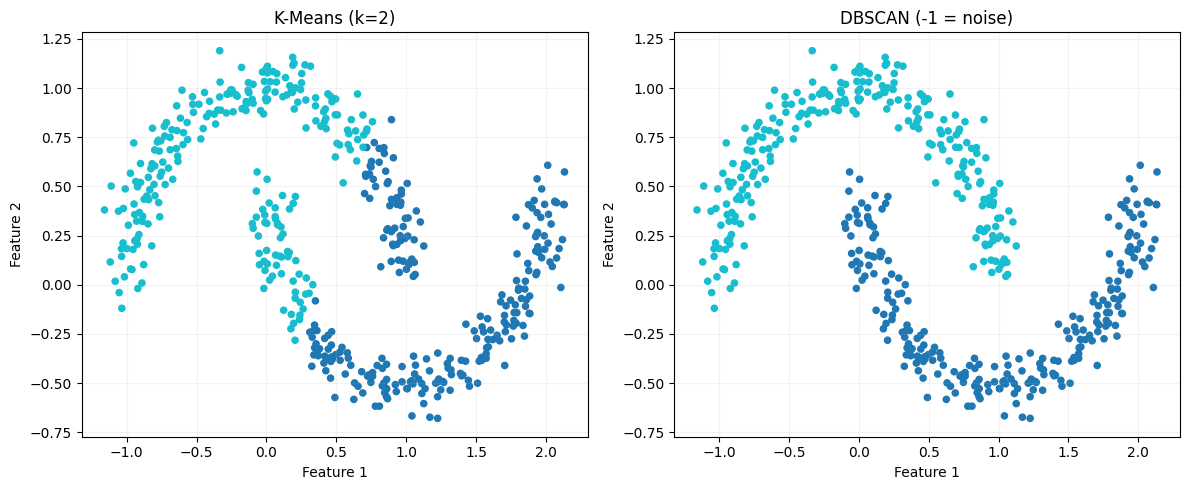

In [9]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

dbscan_labels = DBSCAN(eps=0.20, min_samples=5).fit_predict(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="tab10", s=20)
axes[0].set_title("K-Means (k=2)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

axes[1].scatter(X[:, 0], X[:, 1], c=dbscan_labels, cmap="tab10", s=20)
axes[1].set_title("DBSCAN (-1 = noise)")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

for ax in axes:
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


### Comparison

| Aspect | K-Means | DBSCAN |
|---|---|---|
| Number of clusters | Must specify `k` | Not specified in advance |
| Cluster shape | Best for compact, convex groups | Can find irregular shapes |
| Outliers | Every point is assigned to a cluster | Can label points as noise |
| Main settings | `n_clusters` | `eps`, `min_samples` |
| Scaling | Usually important | Usually important |
| Varying density | Can struggle | Can also struggle |

DBSCAN is not always better. It can struggle when clusters have very different densities, in high-dimensional spaces, or when distance is not meaningful.


## 8. Practical scenario: detect unusual observations

Imagine a retail analytics team examining customer activity using two measures:
- Number of purchases in a period.
- Average basket value.

DBSCAN can identify dense customer behavior groups and flag observations that do not belong to a dense region. A flagged point is not automatically fraud or a bad customer; it is an observation that deserves investigation.

We create a synthetic example for illustration.


Clusters found: 4
Potential outliers: 16


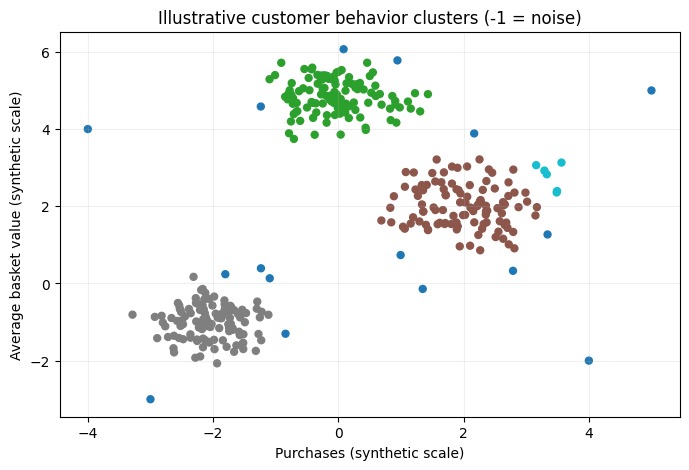

In [10]:
X_customers, _ = make_blobs(
    n_samples=350,
    centers=[[-2, -1], [2, 2], [0, 5]],
    cluster_std=[0.45, 0.65, 0.5],
    random_state=21
)

# Add a few deliberately unusual observations
unusual = np.array([[-4, 4], [4, -2], [5, 5], [-3, -3]])
X_customers = np.vstack([X_customers, unusual])

customer_scaler = StandardScaler()
X_customers_scaled = customer_scaler.fit_transform(X_customers)

customer_model = DBSCAN(eps=0.22, min_samples=6)
customer_labels = customer_model.fit_predict(X_customers_scaled)

print("Clusters found:", len(set(customer_labels)) - (1 if -1 in customer_labels else 0))
print("Potential outliers:", np.sum(customer_labels == -1))

plt.figure(figsize=(8, 5))
plt.scatter(X_customers[:, 0], X_customers[:, 1],
            c=customer_labels, cmap="tab10", s=25)
plt.title("Illustrative customer behavior clusters (-1 = noise)")
plt.xlabel("Purchases (synthetic scale)")
plt.ylabel("Average basket value (synthetic scale)")
plt.grid(alpha=0.2)
plt.show()


**Business discussion**

1. What might make a customer behavior pattern unusual?
2. Should every noise point be treated as suspicious?
3. What additional information would you need before contacting a customer or blocking a transaction?
4. How could an analyst validate whether a cluster is useful?

A responsible workflow investigates outliers with domain knowledge and other signals. DBSCAN alone does not explain why a point is unusual.


## 9. Evaluate clustering carefully

The silhouette score measures how similar an observation is to its own cluster compared with other clusters. It ranges from -1 to 1; higher values generally indicate better separation.

For DBSCAN, calculate it only when there are at least two clusters and not every point is its own cluster. The score below excludes noise points. This is one diagnostic, not a complete measure of clustering quality.


In [11]:
labels_for_score = customer_labels
non_noise_mask = labels_for_score != -1
labels_non_noise = labels_for_score[non_noise_mask]
X_non_noise = X_customers_scaled[non_noise_mask]

n_clusters_non_noise = len(set(labels_non_noise))

if 2 <= n_clusters_non_noise < len(labels_non_noise):
    score = silhouette_score(X_non_noise, labels_non_noise)
    print("Silhouette score (excluding noise):", round(score, 3))
else:
    print("Silhouette score is not defined for this clustering result.")


Silhouette score (excluding noise): 0.66


## 10. Common mistakes and limitations

1. **Choosing `eps` without exploring distances:** Use domain understanding and a k-distance plot as a starting point.
2. **Forgetting feature scaling:** Distance can be dominated by large-range features.
3. **Assuming noise means an error or fraud:** Noise only means the point is not density-connected under the selected settings.
4. **Expecting one parameter setting to fit every density:** DBSCAN can struggle with clusters of substantially different densities.
5. **Using it blindly in high dimensions:** Distances can become less informative as dimensions increase.
6. **Comparing cluster labels as if their numbers have meaning:** Cluster IDs are arbitrary.
7. **Treating one metric as the whole story:** Inspect visualizations, cluster sizes, noise rate, stability, and business usefulness.


## 11. Knowledge check

Try answering these questions before reading the suggested answers.

1. What does DBSCAN stand for?
2. What is a core point?
3. What is the role of `eps`?
4. What is the role of `min_samples`?
5. What does label `-1` mean in scikit-learn DBSCAN?
6. Does DBSCAN require the number of clusters in advance?
7. Why is feature scaling important?
8. Give one advantage DBSCAN has over K-Means.
9. Name one situation where DBSCAN may struggle.
10. Does a DBSCAN noise point automatically mean fraud?

### Suggested answers

1. Density-Based Spatial Clustering of Applications with Noise.
2. A point with at least `min_samples` points in its `eps` neighborhood, counting itself.
3. It sets the neighborhood radius used to decide which points are close.
4. It sets the minimum neighborhood count required for a core point.
5. Noise: a point not assigned to any cluster.
6. No.
7. DBSCAN is distance-based, so feature scales affect distances.
8. It can identify irregularly shaped clusters and mark noise.
9. Clusters with very different densities or high-dimensional data with uninformative distances.
10. No. It is only a point outside the dense regions found under the chosen parameters.

## 12. Mini assignment

Use a dataset of your choice and:

1. Select two or more meaningful numerical features.
2. Explore their distributions and ranges.
3. Handle missing values.
4. Scale the features.
5. Create a k-distance plot.
6. Try at least three `eps` values and two `min_samples` values.
7. Record the number of clusters and noise points for each experiment.
8. Visualize the best candidate result.
9. Compare DBSCAN with K-Means where appropriate.
10. Write a short business interpretation, including what you would investigate before acting on noise points.

**Deliverable:** A Jupyter notebook containing code, visualizations, parameter experiments, observations, and a short conclusion.

---

## Key takeaway

DBSCAN groups observations based on density rather than distance to a centroid. Its strength is discovering irregularly shaped clusters and identifying noise. The practical challenge is selecting meaningful distance and density settings, then validating whether the resulting clusters make sense for the problem.


Case A: clusters=9, noise=126, silhouette=-0.11, ARI=0.22
Case B: clusters=4, noise=7, silhouette=0.85, ARI=0.97
Case C: clusters=4, noise=33, silhouette=0.71, ARI=0.84


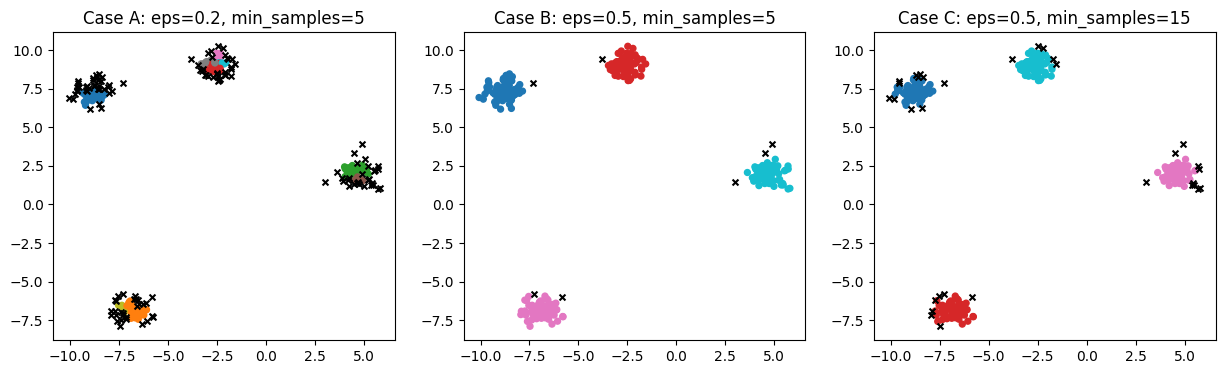

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score, adjusted_rand_score

X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.50, random_state=42)

settings = {"A": (0.2, 5), "B": (0.5, 5), "C": (0.5, 15)}
results = {}

for name, (eps, min_samples) in settings.items():
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    results[name] = labels
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))
    sil = silhouette_score(X, labels)
    ari = adjusted_rand_score(y_true, labels)
    print(f"Case {name}: clusters={n_clusters}, noise={n_noise}, "
          f"silhouette={sil:.2f}, ARI={ari:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, labels) in zip(axes, results.items()):
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise], cmap="tab10", s=18)
    ax.scatter(X[noise, 0], X[noise, 1], c="black", marker="x", s=18)
    ax.set_title(f"Case {name}: eps={settings[name][0]}, min_samples={settings[name][1]}")
plt.show()

In [13]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=300, noise=0.06, random_state=42)
km_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(Xm)
db_labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(Xm)

print("K-Means ARI:", round(adjusted_rand_score(ym, km_labels), 2))
print("DBSCAN ARI:", round(adjusted_rand_score(ym, db_labels), 2))

K-Means ARI: 0.25
DBSCAN ARI: 1.0
